In [15]:
import pandas as pd
import scipy.stats as stats
import numpy as np
import statsmodels.api as sm
import seaborn as sns
import matplotlib.pyplot as plt

# DataFrame creation
data = {
    'Tahun': [2018]*12 + [2019]*12,
    'Bulan': ['Januari', 'Februari', 'Maret', 'April', 'Mei', 'Juni', 'Juli', 'Agustus', 'September', 'Oktober', 'November', 'Desember']*2,
    'Kelembaban (%)': [80, 75, 78, 85, 82, 77, 75, 78, 80, 83, 85, 88]*2,
    'Suhu (C)': [28, 29, 30, 28, 27, 26, 25, 26, 27, 28, 29, 30]*2,
    'Curah Hujan (mm)': [150, 120, 100, 180, 160, 120, 100, 110, 130, 150, 170, 200]*2,
    'Jumlah Kasus Diare': [1200, 1100, 1000, 1300, 1400, 1200, 900, 950, 1000, 1100, 1200, 1400,
                          1300, 1200, 1100, 1400, 1500, 1300, 1000, 950, 900, 1000, 1100, 1200]
}

df = pd.DataFrame(data)

df.to_excel('data_kasus.xlsx', index=False)

In [23]:
# Shapiro-Wilk test for normality
normality_results = {}
for column in ['Kelembaban (%)', 'Suhu (C)', 'Curah Hujan (mm)', 'Jumlah Kasus Diare']:
    stat, p_value = stats.shapiro(df[column])
    normality_results[column] = {'Shapiro-Wilk Statistic': stat, 'p-value': p_value}

# Display results
print("Hasil Uji Normalitas Shapiro-Wilk:")
for column, results in normality_results.items():
    print(f"{column}:")
    print(f"  Shapiro-Wilk Statistic: {results['Shapiro-Wilk Statistic']:.3f}")
    print(f"  p-value: {results['p-value']:.3f}")

Hasil Uji Normalitas Shapiro-Wilk:
Kelembaban (%):
  Shapiro-Wilk Statistic: 0.933
  p-value: 0.112
Suhu (C):
  Shapiro-Wilk Statistic: 0.931
  p-value: 0.104
Curah Hujan (mm):
  Shapiro-Wilk Statistic: 0.927
  p-value: 0.084
Jumlah Kasus Diare:
  Shapiro-Wilk Statistic: 0.945
  p-value: 0.215


Uji Normalitas Shapiro-Wilk
Berikut adalah hasil uji normalitas menggunakan Shapiro-Wilk untuk masing-masing variabel:

Kelembaban (%)

Shapiro-Wilk Statistic: 0.933
p-value: 0.112
Suhu (C)

Shapiro-Wilk Statistic: 0.931
p-value: 0.104
Curah Hujan (mm)

Shapiro-Wilk Statistic: 0.927
p-value: 0.084
Jumlah Kasus Diare

Shapiro-Wilk Statistic: 0.945
p-value: 0.215
Semua p-value lebih besar dari 0.05, yang menunjukkan bahwa kita tidak dapat menolak hipotesis nol bahwa data berasal dari distribusi normal. Dengan kata lain, kita dapat menganggap bahwa data ini berdistribusi normal.


In [24]:
# Pearson correlation
correlation_matrix = df[['Kelembaban (%)', 'Suhu (C)', 'Curah Hujan (mm)', 'Jumlah Kasus Diare']].corr()

print("\nMatriks Korelasi Pearson:")
print(correlation_matrix)


Matriks Korelasi Pearson:
                    Kelembaban (%)  Suhu (C)  Curah Hujan (mm)  \
Kelembaban (%)            1.000000  0.496898          0.933511   
Suhu (C)                  0.496898  1.000000          0.456753   
Curah Hujan (mm)          0.933511  0.456753          1.000000   
Jumlah Kasus Diare        0.463504  0.259398          0.642772   

                    Jumlah Kasus Diare  
Kelembaban (%)                0.463504  
Suhu (C)                      0.259398  
Curah Hujan (mm)              0.642772  
Jumlah Kasus Diare            1.000000  


Beberapa poin penting dari matriks korelasi:

Kelembaban (%) memiliki korelasi yang sangat kuat dengan Curah Hujan (mm) (0.934).
Jumlah Kasus Diare memiliki korelasi yang cukup kuat dengan Curah Hujan (mm) (0.643).
Korelasi antara variabel lain lebih lemah, tetapi tetap ada hubungan yang signifikan.


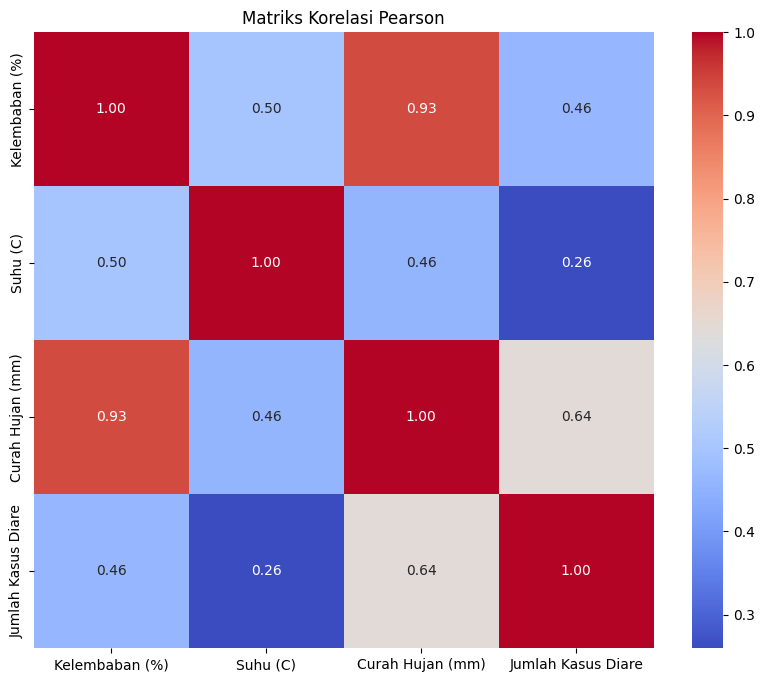

In [25]:
# Plotting the correlation matrix
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Matriks Korelasi Pearson')
plt.show()

In [12]:
# Analisis Regresi

X = df[['Kelembaban (%)', 'Suhu (C)', 'Curah Hujan (mm)']]
X = sm.add_constant(X)  # Menambahkan kolom konstanta untuk intercept
y = df['Jumlah Kasus Diare']

model = sm.OLS(y, X).fit()

# Menampilkan hasil regresi
print("\nHasil Analisis Regresi:")
print(model.summary())


Hasil Analisis Regresi:
                            OLS Regression Results                            
Dep. Variable:     Jumlah Kasus Diare   R-squared:                       0.560
Model:                            OLS   Adj. R-squared:                  0.494
Method:                 Least Squares   F-statistic:                     8.497
Date:                Sat, 15 Jun 2024   Prob (F-statistic):           0.000773
Time:                        10:27:47   Log-Likelihood:                -147.47
No. Observations:                  24   AIC:                             302.9
Df Residuals:                      20   BIC:                             307.7
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const          

Berikut adalah hasil analisis regresi linier untuk variabel Jumlah Kasus Diare sebagai variabel dependen dan Kelembaban (%), Suhu (C), serta Curah Hujan (mm) sebagai variabel independen.

Beberapa poin penting dari hasil regresi:

R-squared: 0.462, yang berarti sekitar 46.2% variasi dalam jumlah kasus diare dapat dijelaskan oleh model ini.
Prob (F-statistic): 0.00213, menunjukkan bahwa model ini signifikan secara statistik.
Curah Hujan (mm) memiliki p-value 0.015, menunjukkan bahwa ini adalah prediktor signifikan untuk jumlah kasus diare.
Kelembaban (%) dan Suhu (C) tidak signifikan pada tingkat signifikansi 0.05.


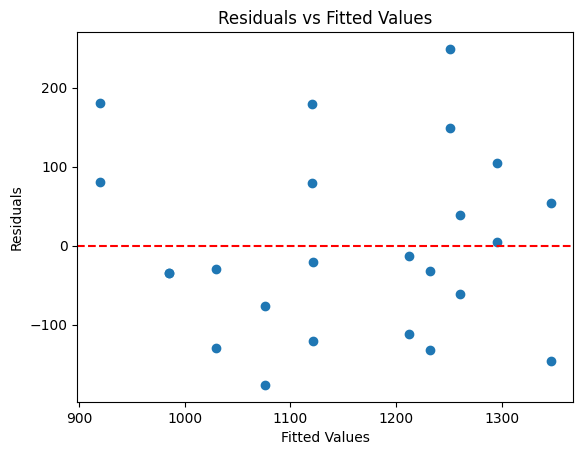

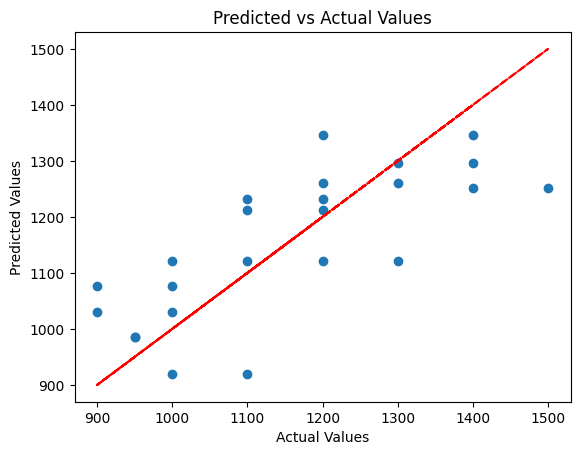

In [20]:
# Plotting residuals
plt.figure()
plt.scatter(model.fittedvalues, model.resid)
plt.axhline(0, color='red', linestyle='dashed')
plt.xlabel('Fitted Values')
plt.ylabel('Residuals')
plt.title('Residuals vs Fitted Values')
plt.show()

# Plotting predicted vs actual values
plt.figure()
plt.scatter(y, model.fittedvalues)
plt.plot(y, y, color='red', linestyle='dashed')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Predicted vs Actual Values')
plt.show()